# Proyek Klasifikasi Gambar: [Simpsons Dataset]
- **Nama:** [Muhammad Bazwa Arigusna]
- **Email:** [arigusnawawa11@gmail.com]
- **ID Dicoding:** [bazwa_arigusna]

## Import Semua Packages/Library yang Digunakan

In [4]:
!pip install split-folders

%matplotlib inline
import os
import sys
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import Callback
import kagglehub
import splitfolders

## Data Preparation

### Data Loading

In [5]:
path_dataset = kagglehub.dataset_download("alexattia/the-simpsons-characters-dataset")
base_simpsons = os.path.join(path_dataset, "simpsons_dataset", "simpsons_dataset")
picked_classes = ['homer_simpson', 'ned_flanders', 'moe_szyslak', 'lisa_simpson', 'bart_simpson', 'marge_simpson', 'krusty_the_clown', 'nelson_muntz', 'ralph_wiggum', 'disco_stu']
subset_dir = "subset_simpsons"
os.makedirs(subset_dir, exist_ok=True)
for c in picked_classes:
    src = os.path.join(base_simpsons, c)
    dst = os.path.join(subset_dir, c)
    if not os.path.exists(dst):
        shutil.copytree(src, dst)
split_dir = "dataset_split_simpsons"
splitfolders.ratio(subset_dir, output=split_dir, seed=99, ratio=(0.8, 0.1, 0.1))
training_path = os.path.join(split_dir, "train")
validation_path = os.path.join(split_dir, "val")
testing_path = os.path.join(split_dir, "test")
classes_list = os.listdir(training_path)


Copying files: 10800 files [00:01, 6246.80 files/s]


### Data Preprocessing

#### Split Dataset

In [6]:
target_dims = (224, 224)
batch_sz = 32
train_augmenter = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)
val_test_processor = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)
train_set_gen = train_augmenter.flow_from_directory(
    directory=training_path,
    target_size=target_dims,
    batch_size=batch_sz,
    class_mode='categorical'
)
val_set_gen = val_test_processor.flow_from_directory(
    directory=validation_path,
    target_size=target_dims,
    batch_size=batch_sz,
    class_mode='categorical',
    shuffle=False
)
test_set_gen = val_test_processor.flow_from_directory(
    directory=testing_path,
    target_size=target_dims,
    batch_size=batch_sz,
    class_mode='categorical',
    shuffle=False
)


Found 8635 images belonging to 10 classes.
Found 1075 images belonging to 10 classes.
Found 1090 images belonging to 10 classes.


## Modelling

In [7]:
total_classes = len(train_set_gen.class_indices)
base_cnn = tf.keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_cnn.trainable = True
for layer in base_cnn.layers[:120]:
    layer.trainable = False
model_simpsons = Sequential([
    base_cnn,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dense(total_classes, activation='softmax')
])
model_simpsons.compile(loss='categorical_crossentropy',
              optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.0001),
              metrics=['accuracy'])
class AkurasiTinggiCallback(Callback):
    def on_epoch_end(self, epoch, logs=None):
        if logs.get('accuracy') >= 0.95 and logs.get('val_accuracy') >= 0.95:
            self.model.stop_training = True
kumpulan_callback = [AkurasiTinggiCallback()]
histori_pelatihan = model_simpsons.fit(
    train_set_gen,
    epochs=20,
    validation_data=val_set_gen,
    callbacks=kumpulan_callback
)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
270/270 ━━━━━━━━━━━━━━━━━━━━ 166s 523ms/step - accuracy: 0.7531 - loss: 0.7591 - val_accuracy: 0.6847 - val_loss: 1.4804
Epoch 2/20
270/270 ━━━━━━━━━━━━━━━━━━━━ 105s 390ms/step - accuracy: 0.9191 - loss: 0.2535 - val_accuracy: 0.6958 - val_loss: 1.7813
Epoch 3/20
270/270 ━━━━━━━━━━━━━━━━━━━━ 109s 405ms/step - accuracy: 0.9509 - loss: 0.1648 - val_accuracy: 0.7926 - val_loss: 1.0023
Epoch 4/20
270/270 ━━━━━━━━━━━━━━━━━━━━ 106s 393ms/step - accuracy: 0.9639 - loss: 0.1206 - val_accuracy: 0.8735 - val_loss: 0.6892
Epoch 5/20
270/270 ━━━━━━━━━━━━━━━━━━━━ 108s 401ms/step - accuracy: 0.9719 - loss: 0.0946 - val_accuracy: 0.8205 - val_loss: 1.0456
Epoch 6/20
270/270 ━━━━━━━━━━━━━━━━━━━━ 110s 407ms/step - accuracy: 0.9774 - loss: 0.0660 - val_accuracy: 0.9209 - val_loss: 0.4463
Epoch 7/20
270/270 ━━━━━━━━━━━━━━━━━━━━ 112s 413ms/step - accuracy: 0.9812 - loss: 0.0563 - val_accuracy: 0.8791 - val_loss: 0.6880
Epoch 8/20
270/270 ━━━━━━━━

## Evaluasi dan Visualisasi

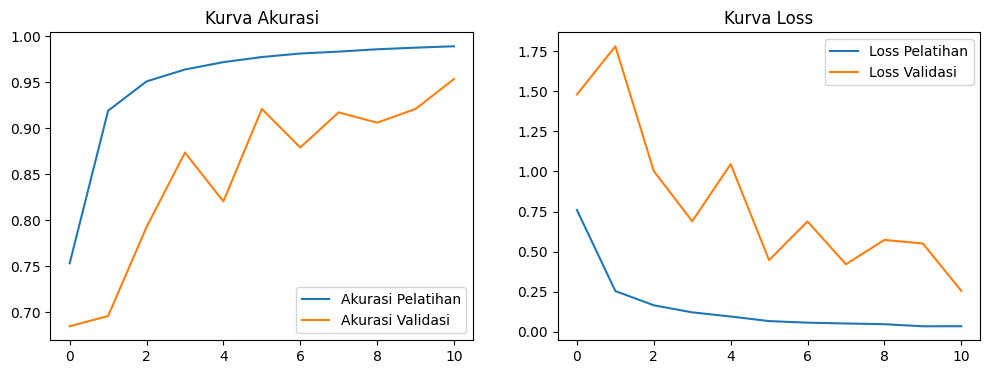

35/35 ━━━━━━━━━━━━━━━━━━━━ 13s 388ms/step - accuracy: 0.9440 - loss: 0.3476


In [8]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(histori_pelatihan.history['accuracy'], label='Akurasi Pelatihan')
plt.plot(histori_pelatihan.history['val_accuracy'], label='Akurasi Validasi')
plt.title('Kurva Akurasi')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(histori_pelatihan.history['loss'], label='Loss Pelatihan')
plt.plot(histori_pelatihan.history['val_loss'], label='Loss Validasi')
plt.title('Kurva Loss')
plt.legend()
plt.show()
loss_uji, akurasi_uji = model_simpsons.evaluate(test_set_gen)


## Konversi Model

In [9]:
import subprocess
import shutil
direktori_ekspor = "submission_simpsons"
os.makedirs(direktori_ekspor, exist_ok=True)
path_saved_model = os.path.join(direktori_ekspor, "saved_model")
if os.path.exists(path_saved_model):
    shutil.rmtree(path_saved_model)
model_simpsons.export(path_saved_model)
konverter_tflite = tf.lite.TFLiteConverter.from_keras_model(model_simpsons)
model_tflite_jadi = konverter_tflite.convert()
path_tflite = os.path.join(direktori_ekspor, 'tflite')
os.makedirs(path_tflite, exist_ok=True)
with open(os.path.join(path_tflite, 'model.tflite'), 'wb') as f:
    f.write(model_tflite_jadi)
peta_kelas = train_set_gen.class_indices
label_terbalik = {v: k for k, v in peta_kelas.items()}
with open(os.path.join(path_tflite, 'label.txt'), 'w') as f:
    for i in range(total_classes):
        f.write(f"{label_terbalik[i]}\n")
model_simpsons.save("model_simpsons.h5")
path_tfjs = os.path.join(direktori_ekspor, "tfjs_model")
if os.path.exists(path_tfjs):
    shutil.rmtree(path_tfjs)
try:
    subprocess.run([sys.executable, "-m", "tensorflowjs.converters.converter", "--input_format=keras", "model_simpsons.h5", path_tfjs], check=True)
except Exception as e:
    pass


Saved artifact at 'submission_simpsons/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  134027844510800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134027844507920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134027844514256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134027844513872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134027844513488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134027844514640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134027844511760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134027844513680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134027844514832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134027844513296: TensorSpec(shape=(), dtype=tf.resource, name=No

## Inference (Optional)

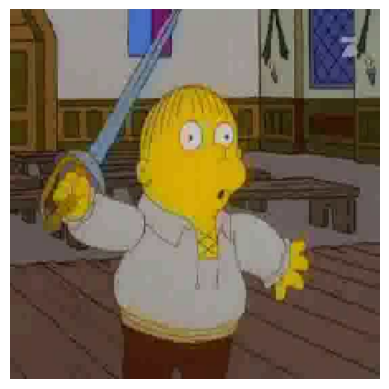

In [10]:
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import random
import tensorflow as tf
jalur_saved = 'submission_simpsons/saved_model'
model_dimuat = tf.saved_model.load(jalur_saved)
fungsi_inferensi = model_dimuat.signatures['serving_default']
kelas_acak = random.choice(classes_list)
direktori_kelas = os.path.join(testing_path, kelas_acak)
nama_gambar_acak = random.choice(os.listdir(direktori_kelas))
jalur_gambar = os.path.join(direktori_kelas, nama_gambar_acak)
citra_uji = image.load_img(jalur_gambar, target_size=(224, 224))
plt.imshow(citra_uji)
plt.axis('off')
plt.show()
arr_citra = image.img_to_array(citra_uji)
arr_citra = np.expand_dims(arr_citra, axis=0)
arr_citra = tf.keras.applications.mobilenet_v2.preprocess_input(arr_citra)
tensor_citra = tf.constant(arr_citra, dtype=tf.float32)
hasil_prediksi = fungsi_inferensi(tensor_citra)
kunci_output = list(hasil_prediksi.keys())[0]
probabilitas = hasil_prediksi[kunci_output].numpy()[0]
indeks_terprediksi = np.argmax(probabilitas)
